# RQ4: Five-Session Cross-Asset Downstream Evaluation

Reader-facing evidence notebook for an Artificial Intelligence and Computer Science capstone. The notebook reads the frozen RQ4 CSV/JSON tables and official PNG figures only; it does not train, tune, or rerun any predictive model or backtest.

## tl;dr

- This RQ4 notebook evaluates **four frozen predictive models across TSLA, AAPL, and NVDA** under one five-session, five-sleeve prediction-to-decision mapping. Development OOF is the primary descriptive result.
- The highest observed Development OOF model return for each asset was **TSLA: Compact LSTM (821.87%)**; **AAPL: Random Forest (135.26%)**; **NVDA: Random Forest (795.76%)**. These are within-asset historical rankings, not claims of universal model superiority.
- **7 of 12** Development asset-model combinations had positive Net Timing Value relative to their own constant-exposure passive reference.
- In the concise later-period check, **1 of 12** asset-model combinations had a positive net return. The later period is retained to show temporal stability, but it is not the headline comparison.
- RQ4 is a **descriptive downstream evaluation**. It uses no RQ4 bootstrap or significance claim and includes no quarterly rolling retraining experiment.

## Context & Methods

**Research question.** To what extent do the predictions generated by Lagged Logistic Regression, Random Forest, XGBoost and Compact LSTM translate into five-session downstream decision performance relative to Buy-and-Hold and transparent moving-average baselines, and how consistent are the observed outcomes across TSLA, AAPL and NVDA?

RQ3 produces a probability after Close $t$ for the class $1[\operatorname{mean}(Close_{t+1:t+5}) > \operatorname{mean}(Close_{t-4:t})]$. RQ4 converts each frozen probability into a common downstream decision using a fixed 0.50 threshold. A long signal is implemented at Open $t+1$ and assigned to one of five self-financing sleeves. That sleeve is next eligible for a decision at Open $t+6$, producing a staggered five-session implementation without leverage or daily cross-sleeve rebalancing.

The four predictive models are Lagged Logistic Regression, Random Forest, XGBoost, and Compact LSTM. EMA8/13 state, SMA10/20 state, and full Buy-and-Hold are transparent reference strategies. RQ4 returns do not reopen RQ3 model selection.

### Exposure-Matched References

Each model is compared with two passive stock/cash references. First, a static Buy-and-Hold allocation is solved ex post so its mean value-weighted exposure matches the model; its result is reported as a return difference, not pure timing value. Second, a synthetic constant-exposure passive path compounds the same average exposure each interval. **Net Timing Value** is the model net return minus this constant-exposure return. Both cumulative-return differences are reported in percentage points (pp), while returns and exposures are reported as percentages. They are descriptive devices and neither is used to tune a model, threshold, or strategy.

### Key Assumptions

- Development OOF predictions are the primary results. The later period is shown briefly as a retrospective temporal-stability check, not a prospectively untouched test.
- TSLA reuses frozen RQ3 probabilities. AAPL and NVDA use the same target, six feature channels, 20-session representation, walk-forward protocol, and fixed threshold, but are fitted independently; this is cross-asset replication, not zero-shot transfer from TSLA.
- A signal is known after Close $t$; execution occurs at Open $t+1$; the assigned sleeve's five open-to-open intervals end at Open $t+6$.
- One-way friction is 10 bps transaction cost plus 5 bps adverse slippage. Cash return, dividends, tax, and additional market impact are excluded.
- The five-session implementation better aligns the decision horizon with RQ3, but the target uses the mean of five future closes rather than the fifth-session endpoint return; the two constructs are related, not mathematically identical.
- Results are descriptive historical observations. No RQ4 bootstrap, p-value, statistical-significance claim, or quarterly rolling-retraining comparison is included.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ASSETS = ['TSLA', 'AAPL', 'NVDA']
PERIODS = ['Development OOF', 'Retrospective audit']
MODELS = [
    'Lagged Logistic Regression', 'Random Forest',
    'XGBoost', 'Compact LSTM'
]
BASELINES = ['EMA8/EMA13 State', 'SMA10/SMA20 State', 'Buy-and-Hold']

def locate_experiment_root():
    cwd = Path.cwd().resolve()
    candidates = [cwd, cwd.parent, cwd / 'v8_4_rq4_five_session_cross_asset']
    for candidate in candidates:
        if (candidate / 'protocol.json').is_file() and (candidate / 'outputs/rq4_headline_metrics.csv').is_file():
            return candidate
    raise FileNotFoundError('Run this notebook from the experiment directory, its notebooks directory, or the parent workspace.')

ROOT = locate_experiment_root()
protocol = json.loads((ROOT / 'protocol.json').read_text(encoding='utf-8'))
metadata = json.loads((ROOT / 'outputs/rq4_experiment_metadata.json').read_text(encoding='utf-8'))
headline = pd.read_csv(ROOT / 'outputs/rq4_headline_metrics.csv', parse_dates=['Path Start', 'Path End'])
model_results = pd.read_csv(ROOT / 'outputs/rq4_model_results.csv', parse_dates=['Path Start', 'Path End'])
matched = pd.read_csv(ROOT / 'outputs/rq4_exposure_matched_buy_hold.csv', parse_dates=['Path Start', 'Path End'])
signals = pd.read_csv(
    ROOT / 'outputs/rq4_signal_ledger.csv',
    parse_dates=['Date', 'Target_Date', 'Execution Date', 'Scheduled End Date']
)

assert metadata['bootstrap_used'] is False
assert metadata['quarterly_rolling_retraining_used'] is False
assert metadata['return_metrics_used_for_model_training_or_selection'] is False
assert metadata['five_self_financing_sleeves'] is True
assert set(headline['Asset']) == set(ASSETS)
assert set(headline['Period']) == set(PERIODS)
assert len(headline) == 42 and len(model_results) == 24 and len(matched) == 24
print('Protocol:', metadata['protocol_id'])
print('Loaded formal result rows:', {'headline': len(headline), 'models': len(model_results), 'exposure_matches': len(matched), 'signals': len(signals)})

Protocol: V8.4-RQ4-FIVE-SESSION-CROSS-ASSET-DESCRIPTIVE
Loaded formal result rows: {'headline': 42, 'models': 24, 'exposure_matches': 24, 'signals': 4971}


## Data

The source tables below report the frozen prediction-origin coverage and the number of five-session decisions that can be executed through Open $t+6$. The final later-period origin for each asset is retained in the signal ledger but excluded from the strategy path when its scheduled endpoint is unavailable.

In [2]:
coverage = (
    signals.groupby(['Asset', 'Period'], sort=False)
    .agg(
        Prediction_Origins=('Date', 'size'),
        Executable_Five_Session_Decisions=('Five-Session Executable', 'sum'),
        Signal_Start=('Date', 'min'),
        Signal_End=('Date', 'max'),
        First_Execution=('Execution Date', 'min'),
        Last_Scheduled_End=('Scheduled End Date', 'max'),
    )
    .reset_index()
)
display(coverage)
assert coverage.loc[coverage.Period.eq('Development OOF'), 'Executable_Five_Session_Decisions'].eq(1250).all()
assert coverage.loc[coverage.Period.eq('Retrospective audit'), 'Executable_Five_Session_Decisions'].eq(406).all()

,Asset,Period,Prediction_Origins,Executable_Five_Session_Decisions,Signal_Start,Signal_End,First_Execution,Last_Scheduled_End
0,TSLA,Development OOF,1250,1250,2019-12-02,2024-11-18,2019-12-03,2024-11-26
1,TSLA,Retrospective audit,407,406,2024-11-26,2026-07-15,2024-11-27,2026-07-22
2,AAPL,Development OOF,1250,1250,2019-12-02,2024-11-18,2019-12-03,2024-11-26
3,AAPL,Retrospective audit,407,406,2024-11-26,2026-07-15,2024-11-27,2026-07-22
4,NVDA,Development OOF,1250,1250,2019-12-02,2024-11-18,2019-12-03,2024-11-26
5,NVDA,Retrospective audit,407,406,2024-11-26,2026-07-15,2024-11-27,2026-07-22


In [3]:
source_inventory = pd.DataFrame([
    {'Formal artefact': 'rq4_headline_metrics.csv', 'Purpose': 'All seven strategies by asset and period', 'Rows': len(headline)},
    {'Formal artefact': 'rq4_model_results.csv', 'Purpose': 'Four-model headline and matched-return fields', 'Rows': len(model_results)},
    {'Formal artefact': 'rq4_exposure_matched_buy_hold.csv', 'Purpose': 'Exposure matching and Timing Value', 'Rows': len(matched)},
    {'Formal artefact': 'rq4_signal_ledger.csv', 'Purpose': 'Frozen prediction-to-execution mapping', 'Rows': len(signals)},
])
display(source_inventory)

,Formal artefact,Purpose,Rows
0,rq4_headline_metrics.csv,All seven strategies by asset and period,42
1,rq4_model_results.csv,Four-model headline and matched-return fields,24
2,rq4_exposure_matched_buy_hold.csv,Exposure matching and Timing Value,24
3,rq4_signal_ledger.csv,Frozen prediction-to-execution mapping,4971


## Results

### Development OOF: Four Predictive Models Across Three Assets

Development OOF is the principal RQ4 comparison. The table keeps return, drawdown, exposure, and exposure-matched Timing Value together so a high raw return is not interpreted without its market participation.

In [4]:
def format_percentage_units(frame, percent_columns, percentage_point_columns=()):
    result = frame.copy()
    for column in percent_columns:
        result[column] = result[column].map(lambda value: f'{100 * value:,.2f}%')
    for column in percentage_point_columns:
        result[column] = result[column].map(lambda value: f'{100 * value:,.2f} pp')
    return result

development_models = model_results.loc[
    model_results['Period'].eq('Development OOF'),
    ['Asset', 'Strategy', 'Net Total Return', 'Annualised Net Return',
     'Maximum Drawdown', 'Average Exposure', 'Matched Net Total Return',
     'Net Return Difference vs Static Matched B&H',
     'Constant-Exposure Passive Net Total Return',
     'Net Timing Value vs Constant-Exposure Passive',
     'Return Rank within Asset-Period']
].sort_values(['Asset', 'Return Rank within Asset-Period'])
display(format_percentage_units(
    development_models,
    ['Net Total Return', 'Annualised Net Return', 'Maximum Drawdown',
     'Average Exposure', 'Matched Net Total Return',
     'Constant-Exposure Passive Net Total Return'],
    ['Net Return Difference vs Static Matched B&H',
     'Net Timing Value vs Constant-Exposure Passive']
))

,Asset,Strategy,Net Total Return,Annualised Net Return,Maximum Drawdown,Average Exposure,Matched Net Total Return,Net Return Difference vs Static Matched B&H,Constant-Exposure Passive Net Total Return,Net Timing Value vs Constant-Exposure Passive,Return Rank within Asset-Period
5,AAPL,Random Forest,135.26%,18.76%,-23.31%,58.04%,99.84%,35.42 pp,123.98%,11.28 pp,1
6,AAPL,XGBoost,131.65%,18.39%,-17.91%,56.42%,95.69%,35.96 pp,119.50%,12.15 pp,2
7,AAPL,Compact LSTM,113.65%,16.48%,-20.85%,55.80%,94.14%,19.50 pp,117.81%,-4.16 pp,3
4,AAPL,Lagged Logistic Regression,83.05%,12.92%,-24.45%,53.17%,87.72%,-4.68 pp,110.72%,-27.67 pp,4
9,NVDA,Random Forest,795.76%,55.36%,-53.50%,60.58%,676.61%,119.15 pp,779.76%,16.00 pp,1
8,NVDA,Lagged Logistic Regression,566.26%,46.39%,-51.64%,56.53%,584.77%,-18.51 pp,673.41%,-107.15 pp,2
11,NVDA,Compact LSTM,551.55%,45.74%,-47.23%,53.61%,525.16%,26.39 pp,603.85%,-52.30 pp,3
10,NVDA,XGBoost,528.21%,44.67%,-59.55%,59.22%,644.49%,-116.28 pp,742.69%,-214.48 pp,4
3,TSLA,Compact LSTM,821.87%,56.26%,-40.12%,47.27%,137.55%,684.32 pp,396.80%,425.07 pp,1
1,TSLA,Random Forest,820.03%,56.20%,-52.96%,56.08%,192.60%,627.44 pp,529.30%,290.73 pp,2


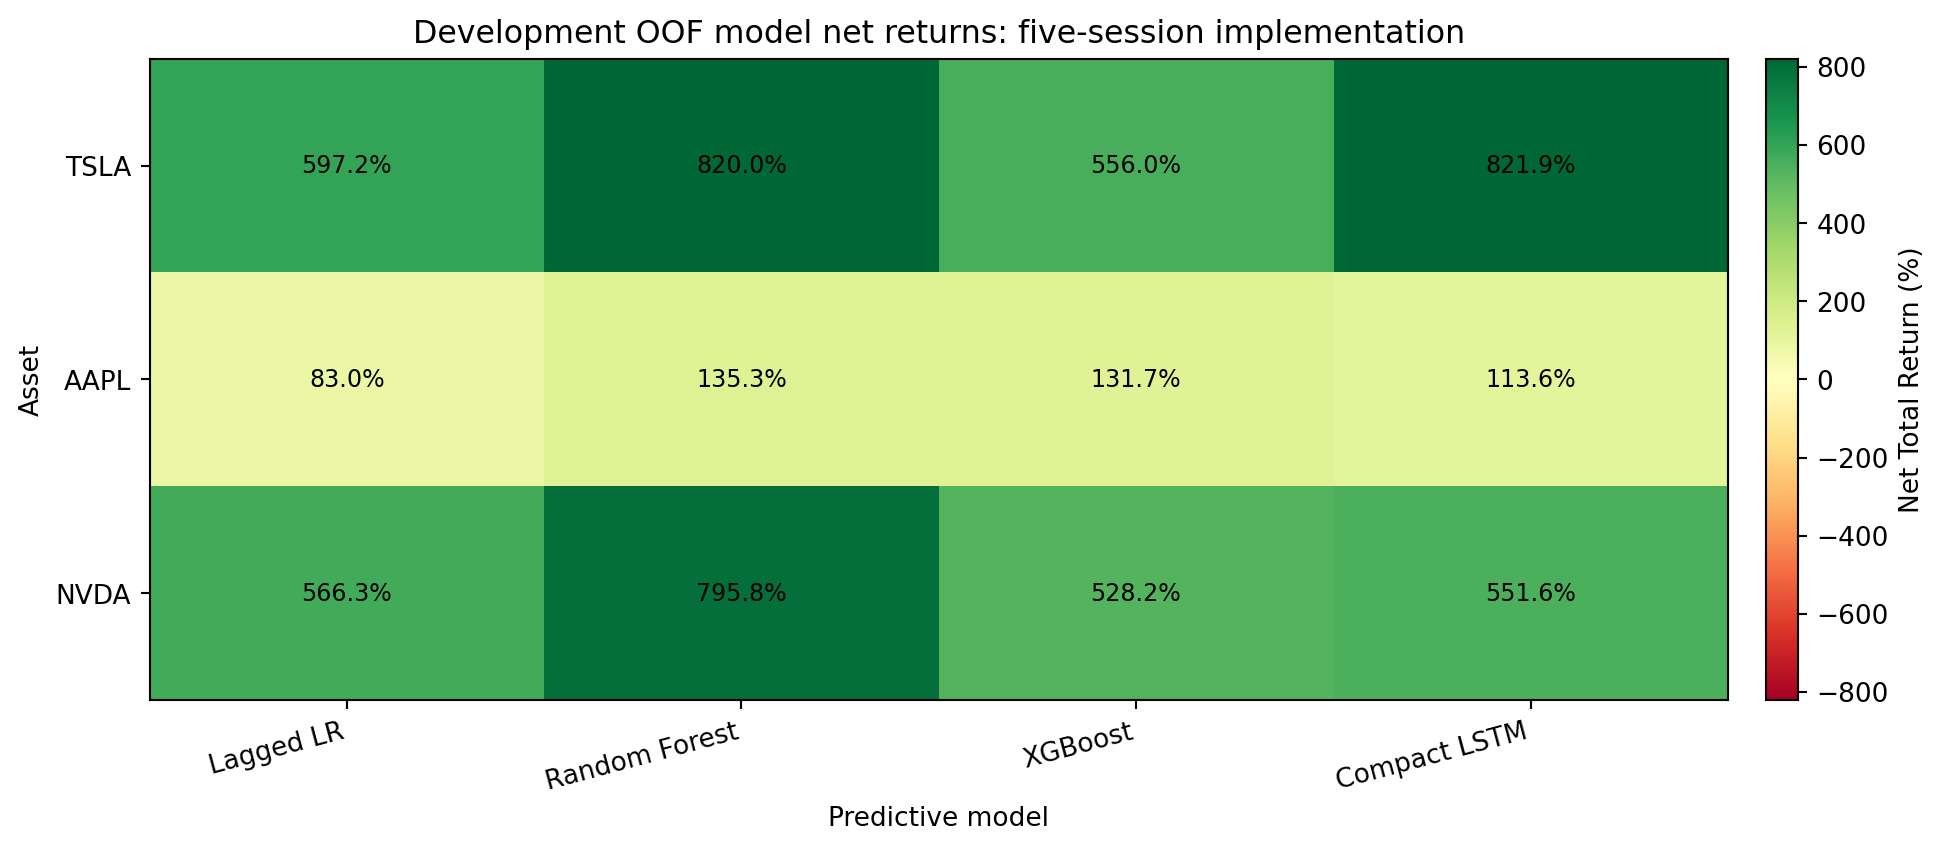

In [5]:
display(Image(filename=str(ROOT / 'figures/rq4_development_model_returns.png'), width=980))

### Development OOF: Exposure-Matched Comparisons

A positive value means that the model's observed dynamic long/cash path returned more than the constant-exposure passive reference. The static matched Buy-and-Hold difference is shown separately. Neither establishes statistical or prospective superiority.

In [6]:
development_matched = matched.loc[
    matched['Period'].eq('Development OOF'),
    ['Asset', 'Model', 'Model Average Exposure',
     'Matched Average Exposure', 'Model Net Total Return',
     'Matched Net Total Return',
     'Net Return Difference vs Static Matched B&H',
     'Constant-Exposure Passive Net Total Return',
     'Net Timing Value vs Constant-Exposure Passive']
].sort_values(['Asset', 'Net Timing Value vs Constant-Exposure Passive'], ascending=[True, False])
display(format_percentage_units(
    development_matched,
    ['Model Average Exposure', 'Matched Average Exposure',
     'Model Net Total Return', 'Matched Net Total Return',
     'Constant-Exposure Passive Net Total Return'],
    ['Net Return Difference vs Static Matched B&H',
     'Net Timing Value vs Constant-Exposure Passive']
))
exposure_error = (matched['Model Average Exposure'] - matched['Matched Average Exposure']).abs().max()
assert exposure_error < 1e-9
print(f'Maximum absolute exposure-matching error: {exposure_error:.3e}')

Maximum absolute exposure-matching error: 2.220e-16


,Asset,Model,Model Average Exposure,Matched Average Exposure,Model Net Total Return,Matched Net Total Return,Net Return Difference vs Static Matched B&H,Constant-Exposure Passive Net Total Return,Net Timing Value vs Constant-Exposure Passive
10,AAPL,XGBoost,56.42%,56.42%,131.65%,95.69%,35.96 pp,119.50%,12.15 pp
9,AAPL,Random Forest,58.04%,58.04%,135.26%,99.84%,35.42 pp,123.98%,11.28 pp
11,AAPL,Compact LSTM,55.80%,55.80%,113.65%,94.14%,19.50 pp,117.81%,-4.16 pp
8,AAPL,Lagged Logistic Regression,53.17%,53.17%,83.05%,87.72%,-4.68 pp,110.72%,-27.67 pp
17,NVDA,Random Forest,60.58%,60.58%,795.76%,676.61%,119.15 pp,779.76%,16.00 pp
19,NVDA,Compact LSTM,53.61%,53.61%,551.55%,525.16%,26.39 pp,603.85%,-52.30 pp
16,NVDA,Lagged Logistic Regression,56.53%,56.53%,566.26%,584.77%,-18.51 pp,673.41%,-107.15 pp
18,NVDA,XGBoost,59.22%,59.22%,528.21%,644.49%,-116.28 pp,742.69%,-214.48 pp
3,TSLA,Compact LSTM,47.27%,47.27%,821.87%,137.55%,684.32 pp,396.80%,425.07 pp
1,TSLA,Random Forest,56.08%,56.08%,820.03%,192.60%,627.44 pp,529.30%,290.73 pp


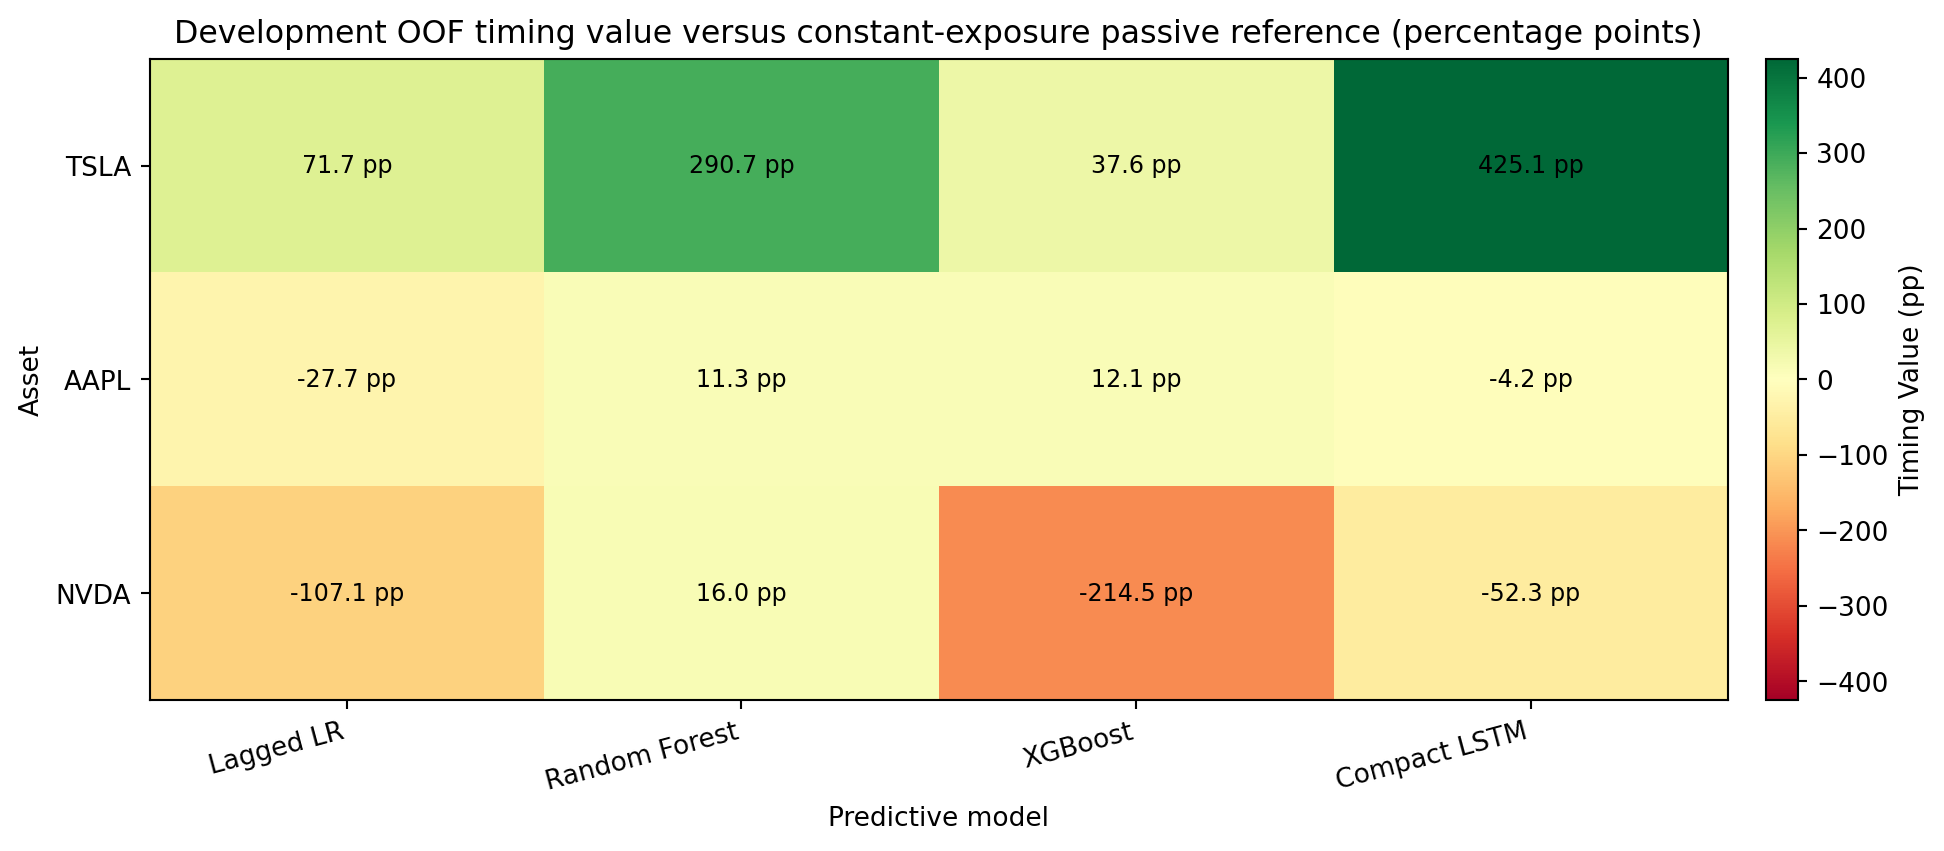

In [7]:
display(Image(filename=str(ROOT / 'figures/rq4_development_timing_value.png'), width=980))

### Development OOF: Transparent Reference Strategies

Buy-and-Hold, EMA8/13 state, and SMA10/20 state provide market and rule-based context. They are reference points rather than additional candidates for return-informed model selection.

In [8]:
development_all = headline.loc[
    headline['Period'].eq('Development OOF'),
    ['Asset', 'Strategy', 'Family', 'Net Total Return',
     'Annualised Net Return', 'Maximum Drawdown', 'Average Exposure']
].sort_values(['Asset', 'Net Total Return'], ascending=[True, False])
display(format_percentage_units(
    development_all,
    ['Net Total Return', 'Annualised Net Return',
     'Maximum Drawdown', 'Average Exposure']
))

,Asset,Strategy,Family,Net Total Return,Annualised Net Return,Maximum Drawdown,Average Exposure
13,AAPL,Buy-and-Hold,Market-context baseline,260.24%,29.37%,-31.00%,100.00%
11,AAPL,EMA8/EMA13 State,Moving-average baseline,144.52%,19.68%,-22.62%,61.65%
8,AAPL,Random Forest,Predictive model,135.26%,18.76%,-23.31%,58.04%
9,AAPL,XGBoost,Predictive model,131.65%,18.39%,-17.91%,56.42%
12,AAPL,SMA10/SMA20 State,Moving-average baseline,123.55%,17.55%,-25.94%,62.23%
10,AAPL,Compact LSTM,Predictive model,113.65%,16.48%,-20.85%,55.80%
7,AAPL,Lagged Logistic Regression,Predictive model,83.05%,12.92%,-24.45%,53.17%
20,NVDA,Buy-and-Hold,Market-context baseline,"2,620.29%",94.22%,-67.27%,100.00%
18,NVDA,EMA8/EMA13 State,Moving-average baseline,"1,117.04%",65.23%,-46.33%,66.59%
19,NVDA,SMA10/SMA20 State,Moving-average baseline,796.21%,55.38%,-47.77%,65.79%


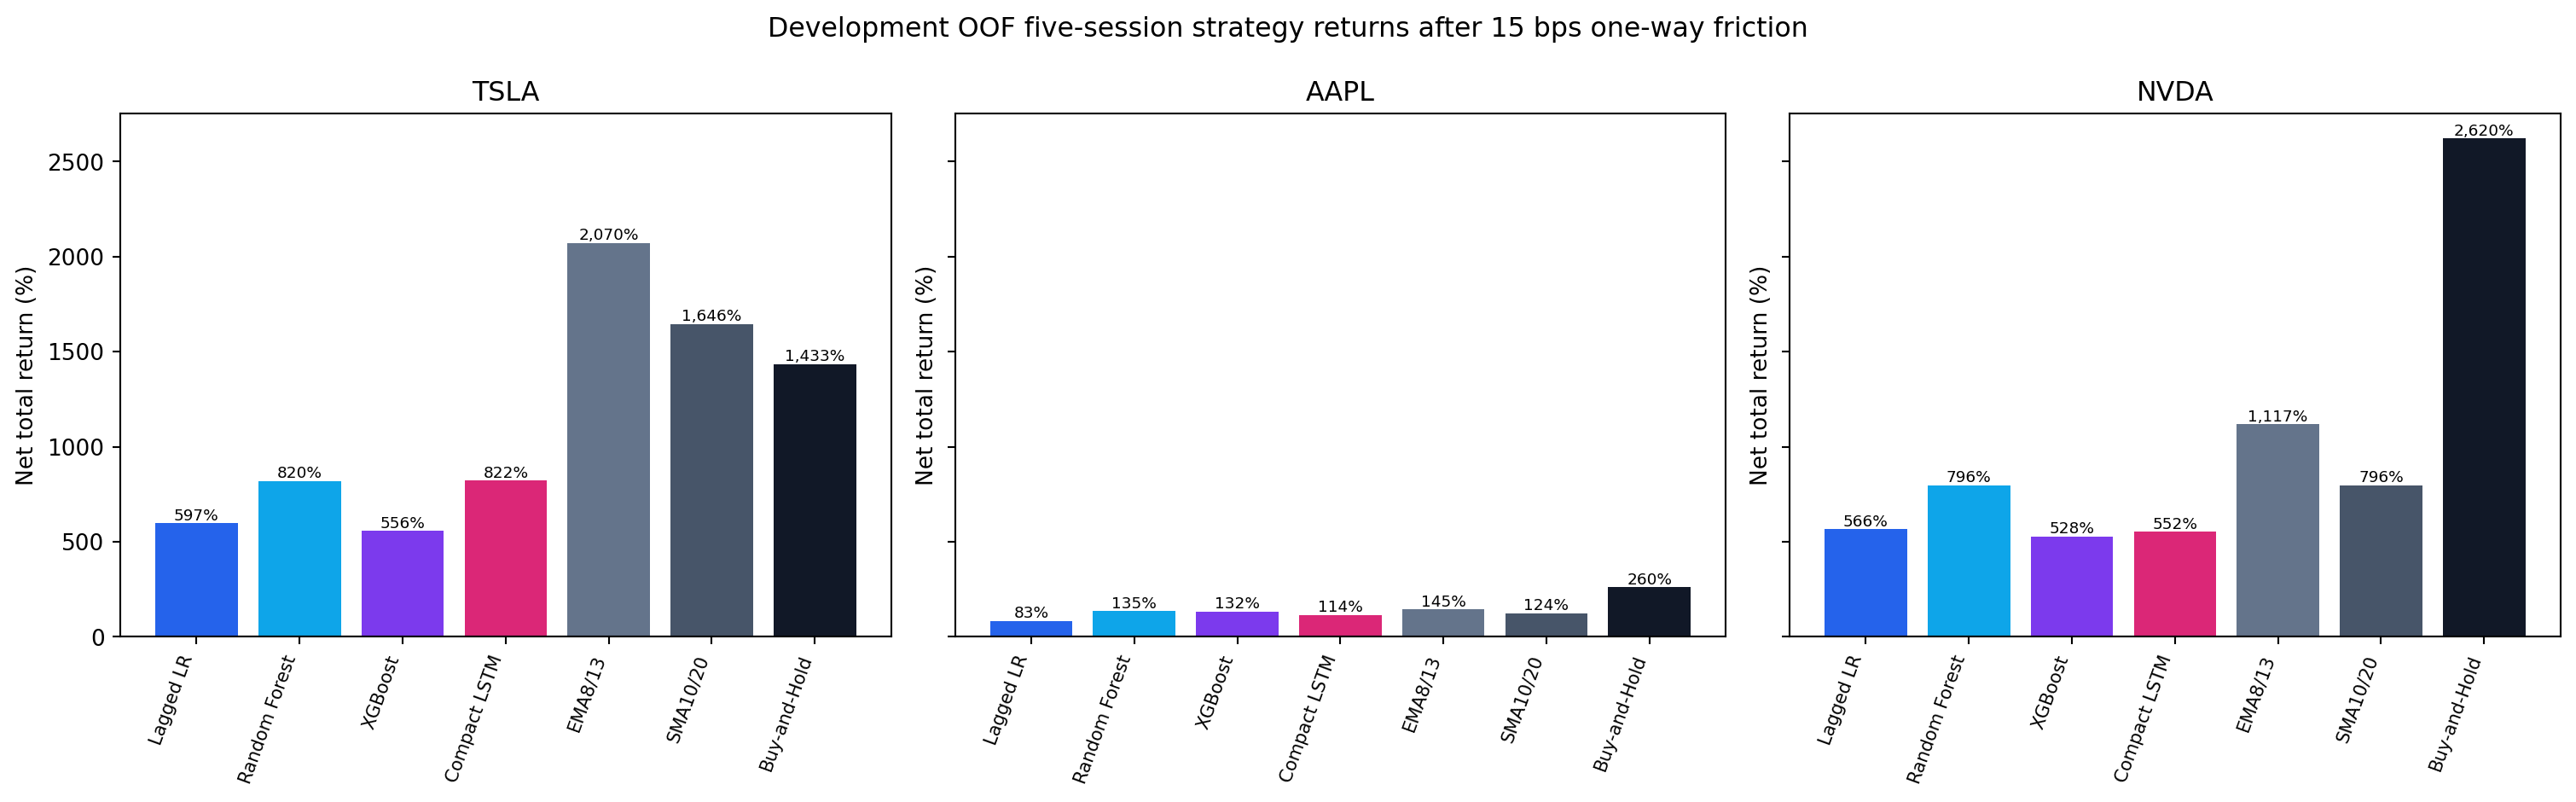

In [9]:
display(Image(filename=str(ROOT / 'figures/rq4_development_strategy_comparison.png'), width=1180))

### Concise Later-Period Check

The later period is retained because temporal stability is relevant to an AI system, but it is not expanded into a second headline study. These observations are retrospective and do not trigger model reselection, threshold changes, or rolling retraining.

In [10]:
later_models = model_results.loc[
    model_results['Period'].eq('Retrospective audit'),
    ['Asset', 'Strategy', 'Net Total Return', 'Maximum Drawdown',
     'Average Exposure',
     'Net Timing Value vs Constant-Exposure Passive',
     'Return Rank within Asset-Period']
].sort_values(['Asset', 'Return Rank within Asset-Period'])
display(format_percentage_units(
    later_models,
    ['Net Total Return', 'Maximum Drawdown',
     'Average Exposure'],
    ['Net Timing Value vs Constant-Exposure Passive']
))

,Asset,Strategy,Net Total Return,Maximum Drawdown,Average Exposure,Net Timing Value vs Constant-Exposure Passive,Return Rank within Asset-Period
16,AAPL,Lagged Logistic Regression,4.41%,-24.03%,54.16%,-17.62 pp,1
17,AAPL,Random Forest,-0.45%,-26.09%,61.27%,-25.30 pp,2
19,AAPL,Compact LSTM,-2.74%,-23.82%,53.20%,-24.39 pp,3
18,AAPL,XGBoost,-8.70%,-29.95%,56.25%,-31.57 pp,4
20,NVDA,Lagged Logistic Regression,-4.70%,-29.42%,54.37%,-36.19 pp,1
21,NVDA,Random Forest,-7.22%,-34.16%,60.76%,-42.03 pp,2
22,NVDA,XGBoost,-10.69%,-34.30%,57.21%,-43.66 pp,3
23,NVDA,Compact LSTM,-11.91%,-32.58%,52.55%,-42.43 pp,4
13,TSLA,Random Forest,-1.13%,-36.21%,44.61%,-12.48 pp,1
15,TSLA,Compact LSTM,-3.91%,-30.98%,43.57%,-15.12 pp,2


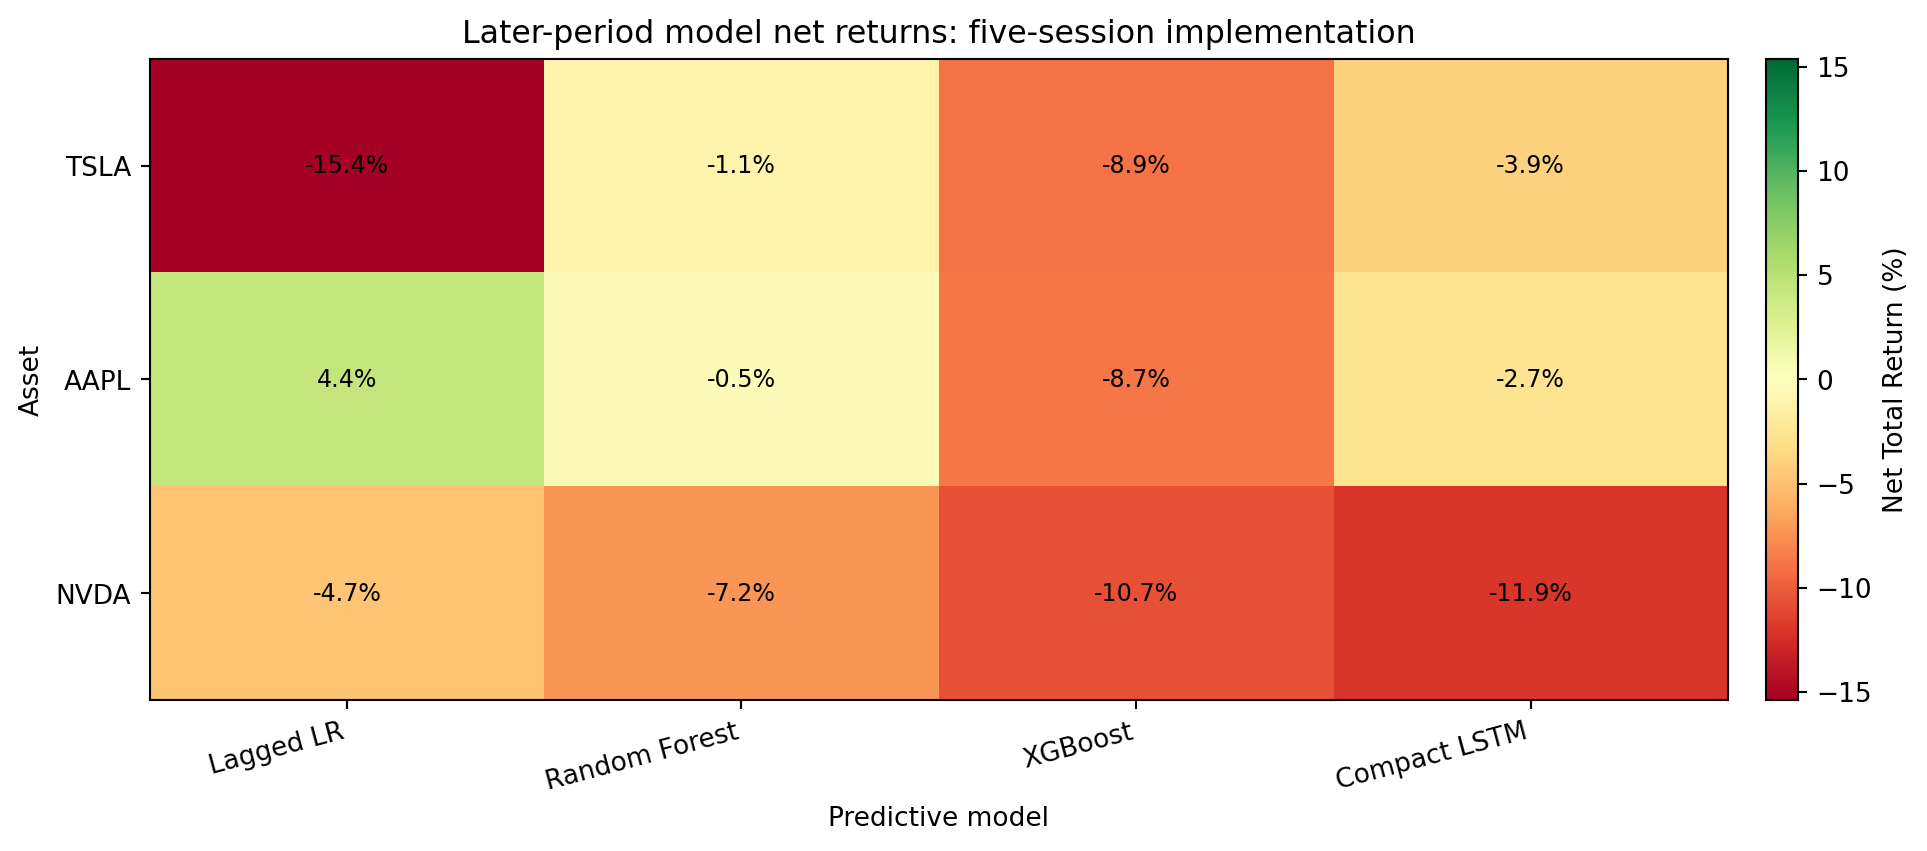

In [11]:
display(Image(filename=str(ROOT / 'figures/rq4_later_period_model_returns.png'), width=980))

## Takeaways

1. **Machine learning remains central to RQ4.** All four frozen model families are evaluated across all three assets; the moving-average and passive paths serve as interpretable baselines.
2. **The downstream mapping now matches the five-session research horizon more closely.** Five staggered sleeves convert daily predictions into overlapping five-session decisions without leverage, although the endpoint return is not identical to the future-mean-price target.
3. **Exposure-matched comparison separates participation from observed timing.** The static matched Buy-and-Hold difference and the constant-exposure Timing Value show that the conclusion depends on benchmark construction, while both remain ex-post descriptive quantities.
4. **Development OOF is the main result; later-period outcomes remain visible.** Changes in later rankings indicate temporal instability rather than invalidating the AI pipeline or justifying selective removal.
5. **Claims stay within a Computer Science capstone boundary.** The notebook demonstrates a reproducible prediction-to-decision application layer. It does not claim statistical significance, live profitability, universal investment superiority, or the benefit of quarterly rolling retraining.